# Знако-ранговая карта Шухарта (Shewhart Signed-Rank Chart)

**Непараметрическая контрольная карта для медианы непрерывного симметричного
распределения; использует и знаки, и ранги отклонений от $\mu_0$.**

Источник: Chakraborti, S. & Graham, M. A. (2019). *Nonparametric Statistical
Process Control*, Wiley.

- § 4.2.1.2 «Shewhart Control Charts Based on Signed-ranks» — стр. 196–202;
- § 4.2.1.2.1 «A Shewhart Signed-rank Chart» — стр. 197;
- определение distribution-free (с оговоркой о симметрии) — стр. 188.

> **Численные примеры книги (4.4–4.5) здесь не воспроизводятся** — они вынесены в
> автотесты `tests/signed_rank/` (один файл — один пример). Этот ноутбук показывает
> теорию и возможности библиотеки `nonparametric-charts`.

## 1. Импорты и настройка

Запуск из каталога `notebooks/`; каталог `src` добавляется в `sys.path` (пакет `nonparametric_charts`).

In [1]:
import sys
from pathlib import Path
from itertools import product

sys.path.append('../src')      # пакет nonparametric_charts (запуск из notebooks/)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from nonparametric_charts.utils.plot_style import (
    ACCENT, ALERT, INK, apply_minimal_latex_style,
)
from nonparametric_charts.utils import DataLoader, DataPreprocessor
from nonparametric_charts.charts.signed_rank_chart import SignedRankChart

apply_minimal_latex_style()
pd.set_option('display.max_columns', 50)
pd.set_option('display.precision', 6)

ROOT = Path('..').resolve()
print('Корень проекта:', ROOT)

Корень проекта: /home/nebolsinvasili/repo/nonparametric-charts


## 2. Теория

### 2.1. Постановка задачи *(§ 4.2.1.2.1, стр. 197)*

Независимые подгруппы размера $n > 1$:

$$X_{i1}, \ldots, X_{in}, \qquad i = 1, 2, \ldots$$

**Предположения (Case K):**

1. Наблюдения независимы внутри подгруппы и между подгруппами.
2. Распределение $F$ непрерывно и **симметрично** относительно неизвестного центра
   $\mu$ (при симметрии среднее и медиана совпадают).
3. Целевое значение $\mu_0$ (IC-медиана) известно.

Из-за симметрии карта — прямой непараметрический аналог параметрической $\bar{X}$-карты.

### 2.2. Абсолютные отклонения и ранги *(стр. 197)*

$$D_{ij} = |X_{ij} - \mu_0|,$$

ранги $R_{ij}$ считаются **внутри каждой подгруппы** отдельно (при совпадениях —
средний ранг).

### 2.3. Знако-ранговая статистика *(стр. 197, ур. 4.5)*

$$SR_i = \sum_{j=1}^{n} \phi(X_{ij} - \mu_0)\, R_{ij}
= S_i^+ - S_i^-, \qquad S_i^\pm = \sum_{\pm} R_{ij}.$$

Так как $S_i^+ + S_i^- = \tfrac{n(n+1)}{2} = S$:

$$\boxed{SR_i = 2T_n^+ - S}, \qquad
T_n^+ = \sum_{j=1}^{n} \Psi(X_{ij} - \mu_0)\, R_{ij} \ \ (\text{ур. 4.4}),$$

где $T_n^+$ — классическая статистика знаковых рангов Уилкоксона.

### 2.4. Распределение $SR_i$ в IC *(стр. 199–200)*

Замкнутой формы нет; распределение получается **точным перебором** $2^n$ знаковых
комбинаций рангов $1, \ldots, n$:

$$SR_i = \sum_{j=1}^{n} s_j\, j, \qquad s_j \in \{-1, +1\},$$

каждая комбинация равновероятна ($2^{-n}$) при симметричном $F$ и $\mu_0$ в центре.
Значения $SR_i \in \{-S, -S+2, \ldots, S\}$ (шаг 2), распределение симметрично:
$P(SR_i = k) = P(SR_i = -k)$.

### 2.5. Моменты *(табл. 4.3, стр. 200)*

$$E(SR_i) = 0, \qquad SD(SR_i) = \sqrt{\frac{n(n+1)(2n+1)}{6}},$$

$$E(T_n^+) = \frac{n(n+1)}{4}, \qquad
SD(T_n^+) = \sqrt{\frac{n(n+1)(2n+1)}{24}}.$$

### 2.6. Контрольные границы *(стр. 198, ур. 4.6)*

$$UCL = +a, \qquad CL = 0, \qquad LCL = -a, \qquad
0 < a \le \frac{n(n+1)}{2} = S.$$

**Правило сигнала:** процесс OOC, если $|SR_i| \ge a$.

### 2.7. Выбор константы $a$ *(стр. 198)*

По книге $a$ — **наименьшее** целое с $P_{\mu_0|IC}(SR_i \ge a) \le FAR_0/2$
(точный подход); достигнутый $FAR \le FAR_0$. При малых $n$ достижимо
только $a = S$ (пример книги: $n = 4 \Rightarrow a = 10$, $FAR = 0.125$).

Библиотека добавляет два вспомогательных подхода: «ближайший» (к $\alpha$) и
«нормальный» (нормальная аппроксимация: наименьшее достижимое $a$ с той же
чётностью, что и $S$, не меньше $z_{1-FAR_0/2}\,\sqrt{n(n+1)(2n+1)/6}$).

### 2.8. Distribution-free свойство *(стр. 188, 197)*

Карта distribution-free для класса непрерывных **симметричных** распределений:
распределение $SR_i$ зависит только от знаков и рангов $|X_{ij} - \mu_0|$ и не зависит
от конкретного вида симметричного $F$. Симметрия — **обязательное** условие.

### 2.9. Распределение длины серии *(стр. 200–201)*

$N \sim \mathrm{GEO}(\theta)$ с $\theta = FAR = P(|SR_i| \ge a)$; характеристики те же:
$ARL = 1/\theta$, $SDRL = \sqrt{1-\theta}/\theta$,
$MRL = \lceil \ln 0.5 / \ln(1-\theta) \rceil$.

## 3. Проверка теории (независимо от класса)

Точное распределение $SR_i$ получаем перебором знаковых комбинаций и сверяем
моменты с табл. 4.3 (стр. 200), а также проверяем симметрию и правило выбора $a$.

In [2]:
def sr_distribution(n):
    '''Точное IC-распределение SR: перебор всех 2^n знаковых комбинаций рангов.'''
    counts = {}
    for signs in product([-1, 1], repeat=n):
        sr = sum(s * j for j, s in enumerate(signs, start=1))
        counts[sr] = counts.get(sr, 0) + 1
    return {k: v / 2 ** n for k, v in counts.items()}


def p_sr_ge(n, a):
    return float(sum(p for v, p in sr_distribution(n).items() if v >= a))


def exact_a_sr(n, far0=0.0027):
    S = n * (n + 1) // 2
    start = 1 if S % 2 else 2
    for a in range(start, S + 1, 2):
        if p_sr_ge(n, a) <= far0 / 2:
            return a, 2.0 * p_sr_ge(n, a)
    return S, 2.0 * p_sr_ge(n, S)


n_check = 5
dist = sr_distribution(n_check)
S = n_check * (n_check + 1) // 2
mean = sum(v * p for v, p in dist.items())
var = sum((v - mean) ** 2 * p for v, p in dist.items())
print(f'Моменты SR при n = {n_check} (S = {S}):')
print(f'  E(SR)   = {mean:.6f}   (теория 0)')
print(f'  Var(SR) = {var:.6f}   (теория n(n+1)(2n+1)/6 = '
      f'{n_check * (n_check + 1) * (2 * n_check + 1) / 6:.6f})')

# Моменты T+ через SR = 2T+ - S
muT = sum(((k + S) / 2) * p for k, p in dist.items())
varT = sum((((k + S) / 2) - muT) ** 2 * p for k, p in dist.items())
print(f'  E(T+)   = {muT:.6f}   (теория n(n+1)/4 = {n_check * (n_check + 1) / 4:.6f})')
print(f'  Var(T+) = {varT:.6f}   (теория n(n+1)(2n+1)/24 = '
      f'{n_check * (n_check + 1) * (2 * n_check + 1) / 24:.6f})')

sym = all(np.isclose(dist.get(k, 0.0), dist.get(-k, 0.0))
          for k in range(-S, S + 1, 2))
print(f'  Симметрия P(SR=k)=P(SR=-k): {sym}')

print('\nТочные константы (FAR0 = 0.0027) и сверка с книгой:')
for n in (4, 5, 10, 13):
    a, far = exact_a_sr(n)
    print(f'  n={n:2d}: a={a:3d}, FAR={far:.6f}, ARL={1 / far:6.1f}')
print('\nКнига: n=4 -> a=S=10, FAR=0.125, ARL=8 (стр. 199);')
print('       n=5 -> a=S=15, FAR=0.062, ARL~16 (стр. 199);')
print('       n=13 -> a=81; в книге напечатано FAR=0.002, ARL=500 — это из')
print('       округления хвоста P(T+>=86)=0.0012207 до 0.001 (табл. B).')
print('       Точные значения: FAR=0.002441, ARL~410 (сверка теории).')

Моменты SR при n = 5 (S = 15):
  E(SR)   = 0.000000   (теория 0)
  Var(SR) = 55.000000   (теория n(n+1)(2n+1)/6 = 55.000000)
  E(T+)   = 7.500000   (теория n(n+1)/4 = 7.500000)
  Var(T+) = 13.750000   (теория n(n+1)(2n+1)/24 = 13.750000)
  Симметрия P(SR=k)=P(SR=-k): True

Точные константы (FAR0 = 0.0027) и сверка с книгой:
  n= 4: a= 10, FAR=0.125000, ARL=   8.0
  n= 5: a= 15, FAR=0.062500, ARL=  16.0
  n=10: a= 55, FAR=0.001953, ARL= 512.0
  n=13: a= 81, FAR=0.002441, ARL= 409.6

Книга: n=4 -> a=S=10, FAR=0.125, ARL=8 (стр. 199);
       n=5 -> a=S=15, FAR=0.062, ARL~16 (стр. 199);
       n=13 -> a=81; в книге напечатано FAR=0.002, ARL=500 — это из
       округления хвоста P(T+>=86)=0.0012207 до 0.001 (табл. B).
       Точные значения: FAR=0.002441, ARL~410 (сверка теории).


## 4. Возможности класса `SignedRankChart`

| Метод | Назначение |
| --- | --- |
| `calculate_limits(a_value=None, approach=None)` | контрольные границы и статистики по подгруппам |
| `compare_approaches()` | сравнение трёх подходов к выбору $a$ |
| `get_sr_table()` | значения $SR_i$ и $T_n^+$ по подгруппам |
| `get_signed_rank_matrix()` | матрица знаковых рангов $\phi(X-\mu_0)\cdot R$ |
| `calculate_signed_rank_test()` | тест Уилкоксона по всем наблюдениям |
| `get_violations()` | найденные сигналы $|SR_i| \ge a$ |
| `get_summary()` | сводка карты |
| `plot(...)`, `plot_comparison(...)` | графики |

> Класс требует $n \ge 2$ (внутри подгруппы нужно ранжировать).

### 4.1. Загрузка данных через `DataLoader` / `DataPreprocessor`

In [3]:
loader = DataLoader('../data/data.csv')
raw = loader.load()
pre = DataPreprocessor(raw)
data, n = pre.get_data_for_chart()

print(pre)
print('Разделитель:', loader.get_detected_separator(),
      '| кодировка:', loader.get_detected_encoding())
print('Сводка:', pre.get_summary())
data.head()

DataPreprocessor(n_subgroups=10, sample_size=14, n_columns=14)
Разделитель: , | кодировка: utf-8
Сводка: {'sample_size': 14, 'num_subgroups': 10, 'num_measurements': 14, 'data_columns': ['x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7', 'x8', 'x9', 'x10', 'x11', 'x12', 'x13', 'x14'], 'index_column': None, 'data_shape': (10, 14), 'missing_values': np.int64(0)}


,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,x11,x12,x13,x14
0,0.152,0.383,0.094,0.067,0.00001,0.316,0.3372,0.811,0.038,0.701,0.137,0.159,0.4571,0.2809
1,0.116,-1.647,0.098,0.642,0.79100,0.988,-0.1760,0.968,0.385,0.361,0.167,0.435,0.9870,0.9940
2,0.322,0.962,0.533,0.798,0.40100,0.838,0.1820,0.632,0.265,0.170,0.783,0.324,0.7710,0.0001
3,0.351,0.829,0.298,-1.892,0.95500,0.688,0.9880,0.477,0.301,0.291,0.565,0.995,0.8890,1.0290
4,0.279,0.003,0.168,22.437,0.87600,-0.127,-0.1370,0.240,0.190,0.289,0.335,0.764,0.2930,0.1120


### 4.2. Проверка симметрии — обязательное условие *(стр. 197–198)*

Перед применением SR-карты убедимся, что распределение данных симметрично.

Асимметрия (skewness) = +10.2547   (0 — симметрия)
Эксцесс (kurtosis)    = +112.3789   (0 — нормальное)
При заметной асимметрии предпочтительна знаковая карта (distribution-free для всех непрерывных F).


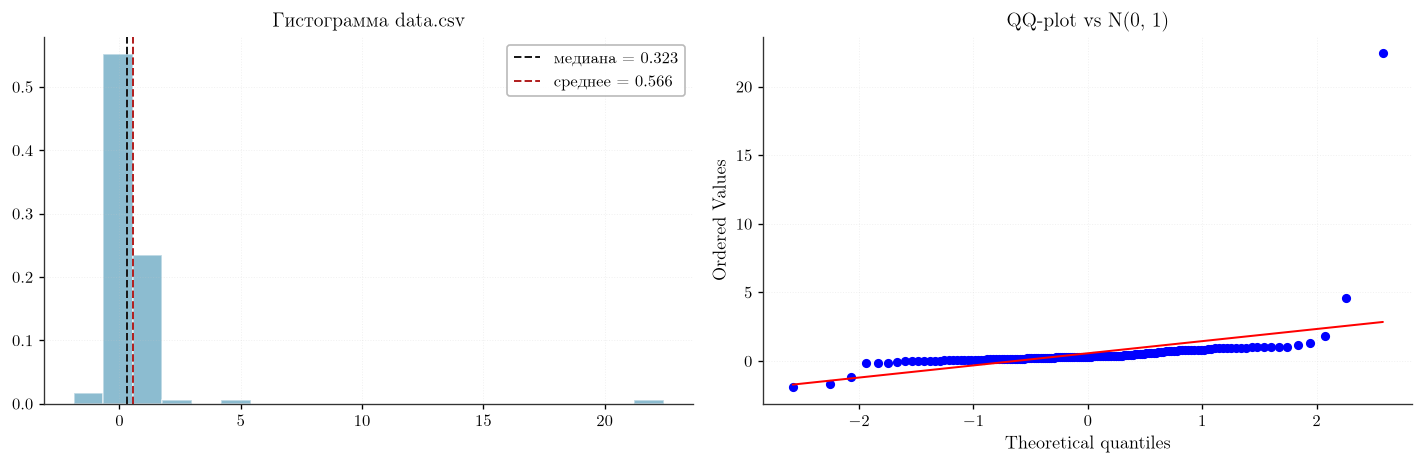

In [4]:
vals = data.values.flatten()
vals = vals[~np.isnan(vals)]
skew = stats.skew(vals)
kurt = stats.kurtosis(vals)
print(f'Асимметрия (skewness) = {skew:+.4f}   (0 — симметрия)')
print(f'Эксцесс (kurtosis)    = {kurt:+.4f}   (0 — нормальное)')
print('При заметной асимметрии предпочтительна знаковая карта (distribution-free '
      'для всех непрерывных F).')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(vals, bins=20, color=ACCENT, alpha=.55, edgecolor='white', density=True)
axes[0].axvline(np.median(vals), color=INK, ls='--',
                label=f'медиана = {np.median(vals):.3f}')
axes[0].axvline(np.mean(vals), color=ALERT, ls='--',
                label=f'среднее = {np.mean(vals):.3f}')
axes[0].set_title('Гистограмма data.csv')
axes[0].legend()
stats.probplot(vals, dist='norm', plot=axes[1])
axes[1].set_title('QQ-plot vs N(0, 1)')
for ax in axes:
    ax.grid(alpha=.25, linestyle=':')
plt.tight_layout()
plt.show()

### 4.3. Построение карты

In [5]:
chart = SignedRankChart(data, sample_size=n, approach='exact', far0=0.0027)
limits = chart.calculate_limits()

print(f'μ₀ = {chart.target_value:.4f}, n = {n}, S = {limits["SR_max"]}')
for key in ['CL', 'UCL', 'LCL', 'a_value', 'FAR', 'ARL_IC', 'MRL_IC']:
    print(f'  {key:>8} = {limits[key]}')

μ₀ = 0.3230, n = 14, S = 105
        CL = 0
       UCL = 91
       LCL = -91
   a_value = 91
       FAR = 0.0023193359375
    ARL_IC = 431.1578947368421
    MRL_IC = 299


### 4.4. График карты

Зоны подписаны в единицах $\sigma$ (соглашение $\sigma = a/3$); истинное
$SD(SR) = \sqrt{n(n+1)(2n+1)/6}$ (табл. 4.3, стр. 200).

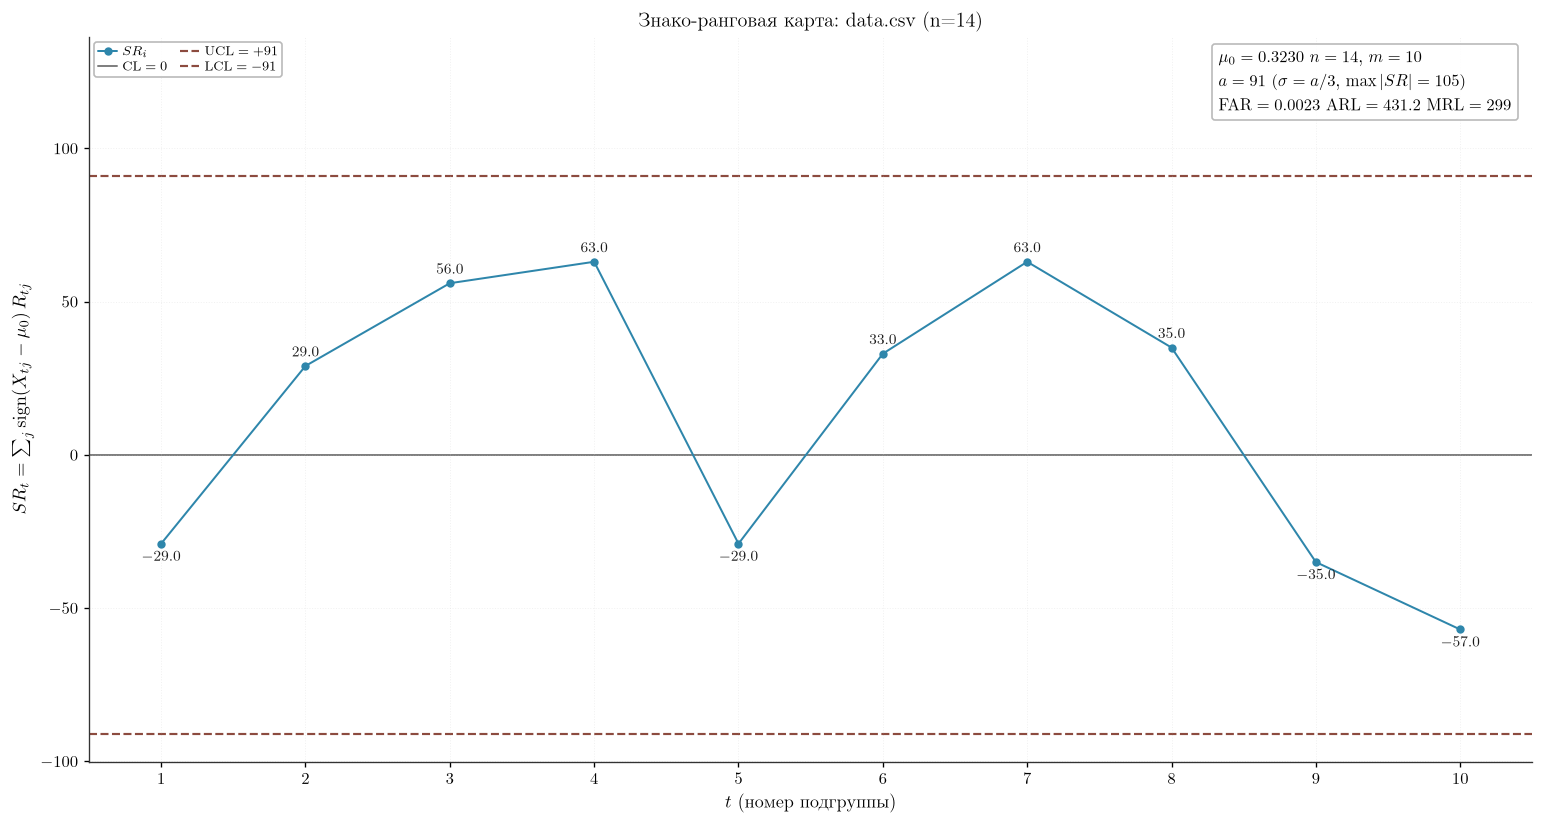

In [6]:
fig, ax = chart.plot(#fill_zones=True,
                     title=f'Знако-ранговая карта: data.csv (n={n})')
plt.show()

### 4.5. Сравнение подходов к выбору $a$

In [7]:
display(chart.compare_approaches().round(6))

,approach,label,a,FAR,ARL_IC,MRL_IC,SR_max,description
0,exact,"Точный (консервативный, FAR₀)",91,0.002319,431.157895,299,105,"P(SR ≥ a) ≤ FAR₀/2, FAR₀ = 0.0027"
1,normal,Нормальная аппроксимация,97,0.000854,1170.285714,811,105,"нормальная аппроксимация z·SD(SR), FAR₀ = 0.0027"
2,nearest,Ближайший (α),62,0.049438,20.227160,14,105,"|P(|SR| ≥ a) − α| → min, α = 0.05"


### 4.6. Тест Уилкоксона и найденные сигналы

In [8]:
test = chart.calculate_signed_rank_test()
print('Знаково-ранговый тест Уилкоксона по всем наблюдениям:')
for key, val in test.items():
    print(f'  {key:>16} = {val}')

print('\nСигналы |SR| >= a:')
print(chart.get_violations() or 'нет')

Знаково-ранговый тест Уилкоксона по всем наблюдениям:
           n_total = 140
            T_plus = 5744.0
          SR_total = 1618.0
           p_value = 0.09241763814716175
       z_statistic = 1.6827802580743612
      target_value = 0.323
       significant = False

Сигналы |SR| >= a:
нет


### 4.7. Таблицы и сводка

In [9]:
print('SR и T+ по подгруппам (слагаемые рангов):')
display(chart.get_sr_table()[['subgroup', 'sr', 'T_plus',
                              'positive', 'negative', 'zero']])

print('Матрица знаковых рангов:')
display(chart.get_signed_rank_matrix())

summary = {k: v for k, v in chart.get_summary().items() if k != 'violations'}
display(pd.DataFrame([summary]).T.rename(columns={0: 'значение'}))

SR и T+ по подгруппам (слагаемые рангов):


,subgroup,sr,T_plus,positive,negative,zero
0,1,-29.0,38.0,5,9,0
1,2,29.0,67.0,9,5,0
2,3,56.0,80.5,9,5,0
3,4,63.0,84.0,10,4,0
4,5,-29.0,38.0,4,10,0
5,6,33.0,69.0,7,7,0
6,7,63.0,84.0,9,5,0
7,8,35.0,70.0,8,6,0
8,9,-35.0,35.0,6,8,0
9,10,-57.0,24.0,3,11,0


Матрица знаковых рангов:


,subgroup,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,x11,x12,x13,x14
0,1,-7.0,4.0,-9.0,-10.0,-12.0,-1.0,2.0,14.0,-11.0,13.0,-8.0,-6.0,5.0,-3.0
1,2,-5.0,-14.0,-6.0,7.0,8.0,12.0,-9.0,10.0,2.0,1.0,-4.0,3.0,11.0,13.0
2,3,-1.5,14.0,7.0,12.0,4.0,13.0,-5.0,8.0,-3.0,-6.0,11.0,1.5,10.0,-9.0
3,4,3.0,8.0,-2.0,-14.0,10.0,7.0,11.0,5.0,-1.0,-4.0,6.0,12.0,9.0,13.0
4,5,-4.0,-9.0,-7.0,14.0,13.0,-11.0,-12.0,-5.0,-6.0,-3.0,1.0,10.0,-2.0,-8.0
5,6,-4.0,10.0,-5.0,13.0,2.0,-6.0,11.0,-9.0,14.0,-3.0,-1.0,12.0,7.0,-8.0
6,7,12.0,11.0,13.0,14.0,7.0,-6.0,10.0,-8.0,5.0,-4.0,-2.0,3.0,9.0,-1.0
7,8,5.0,-9.0,14.0,12.0,6.0,-10.0,11.0,-3.0,1.0,-4.0,-7.0,13.0,8.0,-2.0
8,9,1.0,-9.0,-14.0,-13.0,4.0,12.0,11.0,-6.0,-10.0,-8.0,-7.0,5.0,-3.0,2.0
9,10,-8.0,-5.0,14.0,-12.0,-2.0,1.0,9.0,-3.0,-13.0,-11.0,-4.0,-6.0,-10.0,-7.0


,значение
chart_type,SignedRank
approach,exact
target_value,0.323
n,14
a,91
UCL,91
LCL,-91
CL,0
SR_max,105
FAR,0.002319


### 4.8. Сравнение подходов на диапазоне $n$

In [10]:
fig, axes = chart.plot_comparison(n_range=np.arange(3, 16))
plt.show()

RuntimeError: latex was not able to process the following string:
b'\\u0422\\u043e\\u0447\\u043d\\u044b\\u0439 (FAR\\u2080 = 0.0027)'

Here is the full command invocation and its output:

latex -interaction=nonstopmode -halt-on-error -no-shell-escape file.tex

This is pdfTeX, Version 3.141592653-2.6-1.40.29 (TeX Live 2026/Arch Linux) (preloaded format=latex)
entering extended mode
(./file.tex
LaTeX2e <2025-11-01>
L3 programming layer <2026-01-19>
(/usr/share/texmf-dist/tex/latex/base/fix-cm.sty
(/usr/share/texmf-dist/tex/latex/base/ts1enc.def))
(/usr/share/texmf-dist/tex/latex/base/article.cls
Document Class: article 2025/01/22 v1.4n Standard LaTeX document class
(/usr/share/texmf-dist/tex/latex/base/size10.clo))
(/usr/share/texmf-dist/tex/latex/type1cm/type1cm.sty)
(/usr/share/texmf-dist/tex/latex/base/inputenc.sty)
(/usr/share/texmf-dist/tex/latex/geometry/geometry.sty
(/usr/share/texmf-dist/tex/latex/graphics/keyval.sty)
(/usr/share/texmf-dist/tex/generic/iftex/ifvtex.sty
(/usr/shar

Error in callback <function _draw_all_if_interactive at 0x7fab8fce6f00> (for post_execute), with arguments args (),kwargs {}:


RuntimeError: latex was not able to process the following string:
b'\\u0422\\u043e\\u0447\\u043d\\u044b\\u0439 (FAR\\u2080 = 0.0027)'

Here is the full command invocation and its output:

latex -interaction=nonstopmode -halt-on-error -no-shell-escape file.tex

This is pdfTeX, Version 3.141592653-2.6-1.40.29 (TeX Live 2026/Arch Linux) (preloaded format=latex)
entering extended mode
(./file.tex
LaTeX2e <2025-11-01>
L3 programming layer <2026-01-19>
(/usr/share/texmf-dist/tex/latex/base/fix-cm.sty
(/usr/share/texmf-dist/tex/latex/base/ts1enc.def))
(/usr/share/texmf-dist/tex/latex/base/article.cls
Document Class: article 2025/01/22 v1.4n Standard LaTeX document class
(/usr/share/texmf-dist/tex/latex/base/size10.clo))
(/usr/share/texmf-dist/tex/latex/type1cm/type1cm.sty)
(/usr/share/texmf-dist/tex/latex/base/inputenc.sty)
(/usr/share/texmf-dist/tex/latex/geometry/geometry.sty
(/usr/share/texmf-dist/tex/latex/graphics/keyval.sty)
(/usr/share/texmf-dist/tex/generic/iftex/ifvtex.sty
(/usr/shar

RuntimeError: latex was not able to process the following string:
b'\\u0422\\u043e\\u0447\\u043d\\u044b\\u0439 (FAR\\u2080 = 0.0027)'

Here is the full command invocation and its output:

latex -interaction=nonstopmode -halt-on-error -no-shell-escape file.tex

This is pdfTeX, Version 3.141592653-2.6-1.40.29 (TeX Live 2026/Arch Linux) (preloaded format=latex)
entering extended mode
(./file.tex
LaTeX2e <2025-11-01>
L3 programming layer <2026-01-19>
(/usr/share/texmf-dist/tex/latex/base/fix-cm.sty
(/usr/share/texmf-dist/tex/latex/base/ts1enc.def))
(/usr/share/texmf-dist/tex/latex/base/article.cls
Document Class: article 2025/01/22 v1.4n Standard LaTeX document class
(/usr/share/texmf-dist/tex/latex/base/size10.clo))
(/usr/share/texmf-dist/tex/latex/type1cm/type1cm.sty)
(/usr/share/texmf-dist/tex/latex/base/inputenc.sty)
(/usr/share/texmf-dist/tex/latex/geometry/geometry.sty
(/usr/share/texmf-dist/tex/latex/graphics/keyval.sty)
(/usr/share/texmf-dist/tex/generic/iftex/ifvtex.sty
(/usr/shar

<Figure size 1680x1080 with 2 Axes>

### 4.9. Влияние целевого значения $\mu_0$

In [ ]:
variants = {
    'медиана (по умолчанию)': chart.target_value,
    'среднее': float(data.values.flatten().mean()),
    '0.0': 0.0,
}
rows = []
for name, mu0 in variants.items():
    ch = SignedRankChart(data, sample_size=n, target_value=mu0,
                         approach='exact')
    ch.calculate_limits()
    sr = ch.subgroups['sr'].values
    rows.append({
        'вариант': name, 'μ₀': mu0, 'sum(SR)': float(sr.sum()),
        'a': ch.control_limits['a_value'], 'сигналов': len(ch.get_violations()),
    })
display(pd.DataFrame(rows))

,вариант,μ₀,sum(SR),a,сигналов
0,медиана (по умолчанию),0.323000,129.0,91,0
1,среднее,0.565938,-442.0,91,2
2,0.0,0.000000,936.0,91,7


### 4.10. Проверка инвариантов (capability check)

In [ ]:
checks = {
    'CL = 0': limits['CL'] == 0,
    'UCL = +a': limits['UCL'] == limits['a_value'],
    'LCL = −a': limits['LCL'] == -limits['a_value'],
    '0 < a ≤ S': 0 < limits['a_value'] <= limits['SR_max'],
    'FAR ∈ (0, 1]': 0.0 < limits['FAR'] <= 1.0,
    'ARL = 1/FAR': np.isclose(limits['ARL_IC'] * limits['FAR'], 1.0),
    'FAR = 2·P(SR ≥ a)': np.isclose(limits['FAR'],
                                    min(2 * p_sr_ge(n, limits['a_value']), 1.0)),
}
for name, ok in checks.items():
    print(('[OK]   ' if ok else '[FAIL] ') + name)
assert all(checks.values()), 'Инварианты карты нарушены'

[OK]   CL = 0
[OK]   UCL = +a
[OK]   LCL = −a
[OK]   0 < a ≤ S
[OK]   FAR ∈ (0, 1]
[OK]   ARL = 1/FAR
[OK]   FAR = 2·P(SR ≥ a)


## 5. Итог

| Величина | Формула | Источник |
| --- | --- | --- |
| Статистика Уилкоксона | $T_n^+ = \sum \Psi(X-\mu_0) R$ | ур. 4.4, стр. 197 |
| Знако-ранговая статистика | $SR_i = 2T_n^+ - S$ | ур. 4.5, стр. 197 |
| Моменты | $E(SR_i) = 0$, $SD(SR_i) = \sqrt{n(n+1)(2n+1)/6}$ | табл. 4.3, стр. 200 |
| Границы | $LCL = -a$, $CL = 0$, $UCL = +a$ | ур. 4.6, стр. 198 |
| Выбор $a$ | $P(SR \ge a) \le FAR_0/2$ (наименьшее) | стр. 198 |
| Длина серии | $N \sim \mathrm{GEO}(FAR)$ | стр. 200–201 |

**Выводы.**

1. SR-карта distribution-free только для непрерывных **симметричных** распределений;
   при асимметрии — используйте знаковую карту.
2. Она мощнее знаковой, но требует симметрии и обычно бо́льшего $n$.
3. Примеры 4.4–4.5 проверяются автотестами `tests/signed_rank/`.